In [9]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (Input, Dense, Conv2D, Flatten, MaxPooling2D, Dropout)
from tensorflow.keras.utils import to_categorical

In [10]:
import random

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

In [11]:
SEED = 69

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [12]:
DATA_DIR = Path("images")

deleted = 0

for path in DATA_DIR.rglob("*"):
    if path.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]:
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            path.unlink()
            deleted += 1

print("Corrupted images deleted:", deleted)

Corrupted images deleted: 0


In [15]:
dataset = tf.keras.utils.image_dataset_from_directory(
    "images",
    image_size=(64, 64),
    batch_size=None
)

Found 2033 files belonging to 1 classes.


In [16]:
X = []
y = []
for image, label in dataset:
    X.append(image.numpy())
    y.append(label.numpy())

In [17]:
import numpy as np
X = np.array(X)
y = np.array(y)

In [18]:
X.shape


(2033, 64, 64, 3)

In [19]:

y.shape

(2033,)

In [20]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [21]:
X_train.shape

(1626, 64, 64, 3)

In [22]:

X_train = X_train / 255
X_test = X_test / 255

In [23]:
y_train = to_categorical(y_train, 12)
y_test = to_categorical(y_test, 12)

In [24]:
input_shape = X_train.shape[1:]
num_classes = y_train.shape[1]

In [27]:
model = Sequential()
model.add(Input(shape=input_shape))

model.add(Conv2D(32, (3, 3), activation="relu"))
model.add(MaxPooling2D(2, 2))

model.add(Conv2D(64, (3, 3), activation="relu"))
model.add(MaxPooling2D(2, 2))

model.add(Flatten())

model.add(Dense(128, activation="relu"))
model.add(Dropout(0.3))

model.add(Dense(num_classes, activation="softmax"))
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [28]:
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,626,700 (6.21 MB)

 Trainable params: 1,626,700 (6.21 MB)

 Non-trainable params: 0 (0.00 B)

In [29]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.9777 - loss: 0.0810 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 2/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 3/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 4/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 5/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 6/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 7/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 1.0000 - loss: 2.6593e-09 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 8/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accura

In [30]:
model2 = Sequential()
model2.add(Input(shape=input_shape))

model2.add(Conv2D(32, (3, 3), activation="relu"))
model2.add(MaxPooling2D(2, 2))

model2.add(Conv2D(64, (3, 3), activation="relu"))
model2.add(MaxPooling2D(2, 2))

model2.add(Flatten())

model2.add(Dense(128, activation="relu"))
model2.add(Dropout(0.5))

model2.add(Dense(num_classes, activation="softmax"))
model2.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [31]:
history2 = model2.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.9754 - loss: 0.0733 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 2/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 3/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 4/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 1.0000 - loss: 3.6680e-10 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 5/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 6/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 1.0000 - loss: 9.1699e-11 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 7/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 1.0000 - loss: 9.1699e-11 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 8/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accura

In [32]:
y_pred = model.predict(X_test)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


In [33]:
y_pred_classes = np.argmax(y_pred, axis=1)
y_test_classes = np.argmax(y_test, axis=1)

In [34]:
from sklearn.metrics import (accuracy_score, precision_score,recall_score, f1_score, classification_report, confusion_matrix)


In [35]:

accuracy = accuracy_score(y_test_classes, y_pred_classes)
accuracy

1.0

In [36]:

precision = precision_score(y_test_classes, y_pred_classes, average="weighted")
precision

1.0

In [37]:
recall = recall_score(y_test_classes, y_pred_classes, average="weighted")
recall

1.0

In [39]:
classes = dataset.class_names
print(classes)

['images']


In [40]:
print(classification_report(
    y_test_classes,
    y_pred_classes,
    target_names=classes
))

              precision    recall  f1-score   support

      images       1.00      1.00      1.00       407

    accuracy                           1.00       407
   macro avg       1.00      1.00      1.00       407
weighted avg       1.00      1.00      1.00       407



c:\Users\lenovo\OneDrive\Desktop\skillshikshya\DSML\.venv\Lib\site-packages\sklearn\metrics\_classification.py:614: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


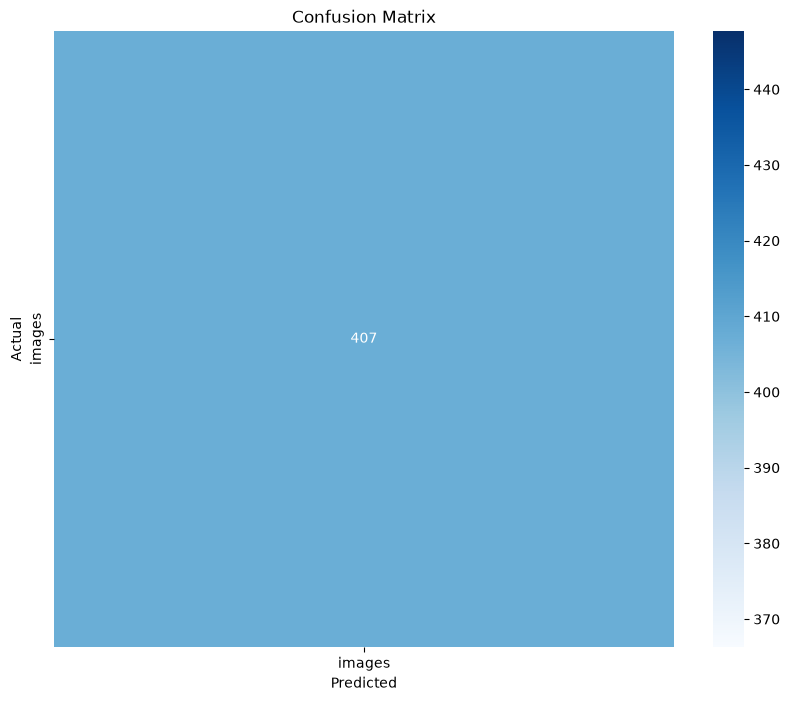

In [41]:
import seaborn as sns
cm = confusion_matrix(y_test_classes, y_pred_classes)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

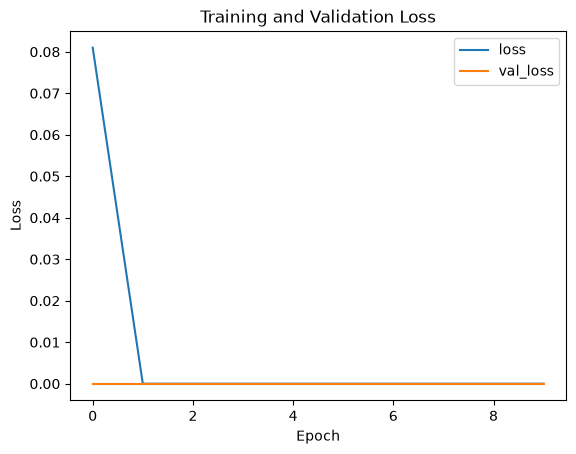

In [42]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(history.history)

df[["loss", "val_loss"]].plot(kind="line")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()